## Tarea #: 1 (Machine learning 1. Especialización de Big Data y Analytics)

Tema: Exploración avanzada de datos, PCA, regresión y análisis crítico multivariado

Por: Maria Alejandra Colorado Ríos


## Punto 1.1.

Calcular la media, mediana, desviación estándar, moda y el número de repeticiones de la moda para las variables numéricas y categóricas del dataset. Realice un análisis crítico detallado sobre las implicaciones de estas medidas de tendencia central y dispersión respecto a la distribución e inequidad socioeconómica entre las ciudades.

Importar y preparar los datos

In [6]:
from pathlib import Path

import pandas as pd

ruta = Path("../../docs/analisisCiudades.xlsx")
datos = pd.read_excel(ruta, sheet_name="datos_originales")
print(f"Archivo: {ruta.as_posix()}")
print(f"Ciudades: {len(datos)}")
#datos

Archivo: ../../docs/analisisCiudades.xlsx
Ciudades: 30


Separar las variables numéricas y categóricas

In [7]:
# Variables numéricas
variables_numericas = [
    'GDP (USD Billion)',
    'Population (Millions)',
    'Unemployment Rate (%)',
    'Average Age',
    'Women (%)',
    'Men (%)',
    'Budget (USD Billion)'
]

# Variables categóricas
variables_categoricas = [
    'City',
    'Initial label',
    'Training'
]

Calcular las medidas para variables numéricas

In [8]:
# Crear una lista para almacenar resultados
resultados_numericos = []

for variable in variables_numericas:

    serie = datos[variable].dropna()

    # Calcular frecuencias
    frecuencias = serie.value_counts()

    # Identificar frecuencia máxima
    frecuencia_maxima = frecuencias.max()

    # Obtener todas las modas
    modas = frecuencias[frecuencias == frecuencia_maxima].index.tolist()

    # Identificar si existe una moda real
    if frecuencia_maxima == 1:
        moda = "Sin moda"
        frecuencia_moda = 0
    else:
        moda = modas
        frecuencia_moda = frecuencia_maxima

    resultados_numericos.append({
        'Variable': variable,
        'n': len(serie),
        'Media': serie.mean(),
        'Mediana': serie.median(),
        'Desviación estándar': serie.std(ddof=0),
        'Moda': moda,
        'Frecuencia de la moda': frecuencia_moda
    })

# Crear DataFrame de resultados
tabla_numerica = pd.DataFrame(resultados_numericos)

# Mostrar resultados
display(tabla_numerica.round(4))

,Variable,n,Media,Mediana,Desviación estándar,Moda,Frecuencia de la moda
0,GDP (USD Billion),30,8.7500,2.65,19.5797,Sin moda,0
1,Population (Millions),30,0.7310,0.39,1.3301,"[0.08, 0.01]",2
2,Unemployment Rate (%),30,13.8333,13.45,2.8956,Sin moda,0
3,Average Age,30,29.2333,29.00,2.2013,[29],6
4,Women (%),30,51.5000,51.00,0.7638,[51],14
5,Men (%),30,48.5000,49.00,0.7638,[49],14
6,Budget (USD Billion),30,1.6500,0.60,3.3932,"[0.5, 0.1]",3


Calcular las medidas para variables categóricas

In [9]:
resultados_categoricos = []

for variable in variables_categoricas:

    serie = datos[variable].dropna()

    # Calcular frecuencias
    frecuencias = serie.value_counts()

    # Frecuencia máxima
    frecuencia_maxima = frecuencias.max()

    # Obtener todas las categorías modales
    modas = frecuencias[frecuencias == frecuencia_maxima].index.tolist()

    # Identificar si existe una moda real
    if frecuencia_maxima == 1:
        moda = "Sin moda"
        frecuencia_moda = 0
        porcentaje_moda = 0
    else:
        moda = modas
        frecuencia_moda = frecuencia_maxima
        porcentaje_moda = (frecuencia_maxima / len(serie)) * 100

    resultados_categoricos.append({
        'Variable': variable,
        'n': len(serie),
        'Moda': moda,
        'Frecuencia de la moda': frecuencia_moda,
        'Porcentaje de la moda': porcentaje_moda
    })

# Crear DataFrame de resultados
tabla_categorica = pd.DataFrame(resultados_categoricos)

# Mostrar resultados
display(tabla_categorica.round(2))

,Variable,n,Moda,Frecuencia de la moda,Porcentaje de la moda
0,City,30,Sin moda,0,0.00
1,Initial label,30,[2],10,33.33
2,Training,30,[Yes],21,70.00


# Análisis punto 1.1

1. Concentración económica y distribución del PIB (GDP)

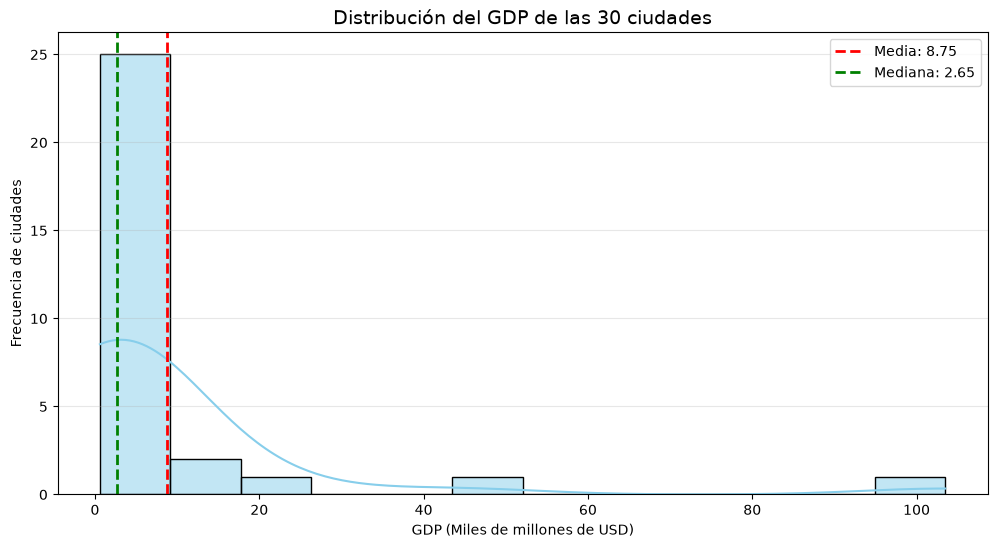

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar la variable GDP
gdp = datos["GDP (USD Billion)"].dropna()

# Calcular medidas estadísticas
media = gdp.mean()
mediana = gdp.median()

# Crear el histograma
plt.figure(figsize=(12, 6))

sns.histplot(
    gdp,
    bins=12,
    kde=True,
    color="skyblue",
    edgecolor="black"
)

# Agregar línea de la media
plt.axvline(
    media,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media:.2f}"
)

# Agregar línea de la mediana
plt.axvline(
    mediana,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {mediana:.2f}"
)

# Configurar el gráfico
plt.title("Distribución del GDP de las 30 ciudades", fontsize=14)
plt.xlabel("GDP (Miles de millones de USD)")
plt.ylabel("Frecuencia de ciudades")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


Se identifica que la media(8,75) es considerablemente superior a la mediana (2.65) para la variable GDP, lo que indica que la distribución está sesgada a la derecha, es decir, existen pocas ciudades con valor total de bienes y servicios producidos muy elevados que incrementan el promedio general. 

Por ejemplo, Bogotá registra un GDP de 103,5 mil millones de dólares, y Medellín de 44,1, mientras que la mayoría de las ciudades presentan valores inferiores a 10 mil millones.

Adicional, la desviación estándar de 19,57 mil millones supera ampliamente la media, lo que evidencia una dispersión muy alta de los datos.

Por lo tanto, esta concentración refleja una posible desigual económica entre ciudades, evidenciadas en sus capacidades productivas, niveles de generación de empleo, inversión y desarrollo empresarial.


2. Diferencias en el tamaño poblacional

## Punto 1.2.

Generar un boxplot para analizar la distribución de las variables clave de la Tabla 1 utilizando las proporciones indicadas a continuación. Identifique y discuta formalmente la presencia de valores atípicos (outliers), su impacto analítico y su interpretación socioeconómica en el contexto urbano.